# GPT-2: a causal Transformer for next-token generation

Given the prompt **“The robot opened the”**, how does a model pick a plausible next token without looking at text that does not exist yet? GPT-2's answer is a stack of **causal** Transformer blocks trained to predict the next token.

### The GPT-2 family

OpenAI released GPT-2 in four sizes. They share the same design and differ only in depth and width:

| Model | L (Layers) | H (Hidden size) | A (Attention heads) | Total parameters | Approx. size (fp32 weights) |
| --- | --- | --- | --- | --- | --- |
| **GPT-2 Small** | 12 | 768 | 12 | 124M | ~0.5 GB |
| **GPT-2 Medium** | 24 | 1024 | 16 | 355M | ~1.4 GB |
| **GPT-2 Large** | 36 | 1280 | 20 | 774M | ~3.1 GB |
| **GPT-2 XL** | 48 | 1600 | 25 | 1.5B | ~6.2 GB |

- All four use a vocabulary of $V = 50{,}257$ tokens, a context of $T = 1{,}024$ tokens, and a per-head width of $H / A = 64$.
- Size is parameters × 4 bytes (fp32), in GB of $10^9$ bytes. It covers the weights only; training needs several times more (see [Fine-tuning GPT-2](../../module3/lectures/fine_tuning/gpt2_fine_tuning.ipynb)).
- The GPT-2 paper reports 117M, 345M, 762M, and 1542M parameters. The counts above are what you get by counting the weights of the released checkpoints, for example with `sum(p.numel() for p in model.parameters())`.

**What you will learn**

1. **Causal language modeling (CLM):** the objective GPT-2 is trained on, and how it differs from BERT's masked language modeling.
2. **The architecture:** how token IDs turn into next-token probabilities, with the tensor shape at every step.
3. **Causal self-attention:** queries, keys, values, heads, and the mask that blocks the future.
4. **Training vs. generation:** why training processes all positions in parallel, while generation produces one token at a time.
5. **Decoding:** greedy, temperature, and top-k, which are choices made at generation time and do not change the weights.

**Prerequisites:** embeddings, matrix multiplication, softmax, cross-entropy, attention. Related notebooks: [Attention Is All You Need](Attention_Is_All_You_Need.ipynb) · [attention mechanisms](attention_mechanisms.ipynb) · [BERT](BERT.ipynb) · [key–value cache](key_value_cache.ipynb) · [GPT-2 lab](../labs/gpt2_causal_lm/gpt2_causal_lm_lab.ipynb).

**Setup:** Python 3, PyTorch, matplotlib (`python -m pip install torch matplotlib`). Everything runs on a CPU in under a minute, using tiny models and no downloads. Toy numbers and toy models are for illustration only; they say nothing about real language. Section 8 is optional and downloads the real GPT-2.

In [2]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

SEED = 42
torch.manual_seed(SEED)
device = torch.device("cpu")   # the tiny model needs no GPU; seeds do not guarantee identical GPU results
print("PyTorch:", torch.__version__, "| device:", device)

PyTorch: 2.4.0+cu121 | device: cpu


## 1. Causal language modeling

### The idea

- A **language model** assigns a probability to text. A phone keyboard that suggests “door” after “The robot opened the” is a small example of one.
- A **causal** language model follows one rule: **each token is predicted only from the tokens before it.** Information flows from past to future, never the other way.

### Why predicting the next token is enough

The chain rule of probability breaks the probability of any text into next-token predictions:

$$P(x_1,\dots,x_T)=\prod_{t=1}^{T}P\!\left(x_t\mid x_1,\dots,x_{t-1}\right)$$

- Each factor is a **next-token distribution** over the vocabulary, conditioned on the prefix.
- The first factor conditions on a start token (GPT-2 uses `<|endoftext|>`).
- The only assumption is a left-to-right order. The model's job is to estimate each factor well.

### The training objective

Training makes the real text as probable as possible, which is the same as minimizing the average **negative log-likelihood** of each real next token:

$$\mathcal{L}=-\frac{1}{T}\sum_{t=1}^{T}\log P_\theta\!\left(x_t\mid x_{<t}\right)$$

| Term | Meaning |
| --- | --- |
| $\mathcal{L}$ | Cross-entropy between the model's softmax output and the actual next token. Lower is better. |
| Perplexity $=e^{\mathcal{L}}$ | “As uncertain as a uniform choice among this many tokens.” |
| Autoregressive | At generation time each chosen token is appended and fed back in as input. |

The cell below applies these formulas to made-up probabilities for “The robot opened the door”.

## 2. How GPT-2 implements causal language modeling

GPT-2 is a **decoder-only Transformer**. Each requirement of causal language modeling maps to one architectural choice:

| Causal LM needs to… | GPT-2 does this with… | Section |
| --- | --- | --- |
| output a next-token distribution at every position | a vocabulary projection: logits of shape `(B, T, V)`, then softmax | 3 |
| use **only the past** | a **causal attention mask**: position `i` can read positions `j ≤ i` only | 4 |
| learn from every position at once | **shifted targets**: the output at position `t` is scored against token `t + 1` | 6 |
| produce text | an **autoregressive loop**: predict, append, repeat | 7 |

> **Why a mask is needed.** In a Transformer, any position can attend to any other. During training the next token is already in the input, so without a mask the model could just read the answer. Section 5 tests for exactly this leak.

### Causal LM (GPT-2) vs. masked LM (BERT) vs. the original Transformer

| | Original encoder–decoder | BERT (masked LM) | GPT-2 (causal LM) |
| --- | --- | --- | --- |
| Components | encoder + decoder with cross-attention | encoder stack | decoder stack, **no** cross-attention |
| Attention | encoder: full · decoder: causal + cross | full (both sides) | causal (left only) |
| Training target | target tokens, given the source | hidden `[MASK]` tokens (~15%) | the next token, at **every** position |
| Positions that give a loss | all target positions | masked positions only | all `T` positions |
| Generates text? | yes, conditioned on the source | not directly | yes: predict, append, repeat |
| Typical use | translation | classification, tagging, QA | generation, prompting |

The figure compares the two attention patterns for five positions.

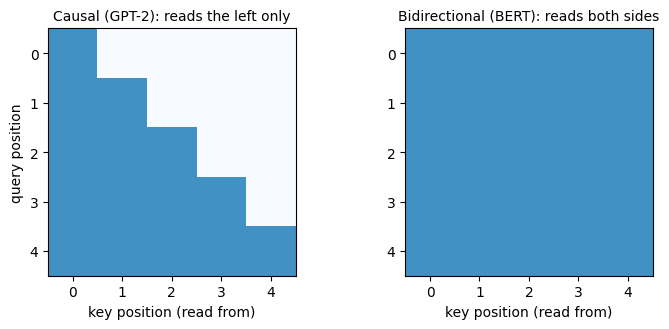

In [3]:
T5 = 5
causal_pattern = ~torch.triu(torch.ones(T5, T5, dtype=torch.bool), diagonal=1)   # True = allowed to read
full_pattern = torch.ones(T5, T5, dtype=torch.bool)

fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.4))
for ax, pattern, title in zip(axes, (causal_pattern, full_pattern),
                              ("Causal (GPT-2): reads the left only", "Bidirectional (BERT): reads both sides")):
    ax.imshow(pattern.float(), cmap="Blues", vmin=0, vmax=1.6)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("key position (read from)")
    ax.set_xticks(range(T5)); ax.set_yticks(range(T5))
axes[0].set_ylabel("query position")
plt.tight_layout(); plt.show()

**Reading the figure:** dark squares are the positions a query (row) may read from (column).

- **Causal:** lower triangle. The answer token is in the input, so the mask is what stops the model from reading it.
- **Bidirectional:** full square. This is safe for BERT because its objective replaces the answer token with `[MASK]` before the model sees it.

**Two common confusions**

- **`[MASK]` is not the attention mask.** `[MASK]` is a *token* that BERT puts into its input. GPT-2's attention mask is a *rule* about which positions may read which; it changes nothing in the input.
- **Neither objective is “better”.** The causal objective matches the task of generating text. The masked objective uses context from both sides, which helps understanding tasks, but it gets fewer training signals per sequence.

### From the original decoder to the GPT-2 block

```text
Encoder block            Decoder block                  Decoder-only (GPT-2) block
─────────────            ─────────────                  ──────────────────────────
self-attention           masked self-attention          masked self-attention
(all positions)          cross-attention ← encoder      (no encoder → no cross-attention)
feed-forward             feed-forward                   feed-forward
```

- GPT-2 stacks the right-hand block. Even GPT-2 small has 12 of them, compared with 6 + 6 in the original base Transformer.
- A GPT-2 **prompt** is conditioning context, not encoder output. GPT-2 was trained only to predict the next token, not to follow instructions.
- Sources: [GPT-2 report](https://cdn.openai.com/better-language-models/language-models.pdf) · [Hugging Face docs](https://huggingface.co/docs/transformers/model_doc/gpt2) · [The Illustrated GPT-2](https://jalammar.github.io/illustrated-gpt2/).

## 3. The architecture: from token IDs to logits

### Tokens and embeddings

- **Tokens:** GPT-2 uses byte-level BPE. A token can be a word, part of a word, punctuation, or a piece that includes a leading space.
- **Original GPT-2:** 50,257-token vocabulary, 1,024-token context window. GPT-2 small has 12 blocks, width 768, and 12 heads.
- **Input:** IDs of shape `(B, T)`. Each ID gets a learned token vector, and each position gets a learned position vector. The two are added:

$$X_{b,t}=E_{\mathrm{token}}[\mathrm{id}_{b,t}]+E_{\mathrm{position}}[t],\qquad X\in\mathbb{R}^{B\times T\times D}$$

- Unlike the fixed sinusoidal positions in the original Transformer, GPT-2's position embeddings are **learned**. Positions are limited to the context length.
- Most modern LLMs (Llama, Mistral, Qwen) instead use **RoPE**, which rotates queries and keys inside attention. See [positional encodings](positional_encodings.ipynb).

### The block stack

```text
Token IDs (B, T)
    │  token embedding + learned position embedding
    ▼
Representations (B, T, D)
    │
    ├─ repeat N times ──────────────────────────────────────────────┐
    │   layer norm → causal multi-head self-attention → residual add │
    │   layer norm → feed-forward network (GELU) → residual add      │
    └─────────────────────────────────────────────────────────────────┘
    │ final layer norm
    ▼
Hidden states (B, T, D) → vocabulary projection → logits (B, T, V)
```

| Component | What it does | Mixes positions? |
| --- | --- | --- |
| Token + position embedding | Turns each ID into a `D`-dim vector that also encodes its position | no |
| Layer norm (**pre-norm**) | Normalizes the input to each sublayer | no |
| Causal self-attention | Each position gathers information from itself and **earlier** positions | **yes, and only here** |
| Feed-forward network | `D → 4D → GELU (tanh approx.) → D`, applied to each position separately | no |
| Residual add | Adds each sublayer's output back to its input, so information has a direct path through the stack | no |
| Final layer norm + vocabulary projection | `D → V` scores (**logits**). The weights are **tied** to the token embedding, saving `V × D` parameters | no |

> **Key idea:** attention is the **only** place where positions exchange information. Everything else acts on each position independently. That is why a single mask inside attention is enough to make the whole model causal.

- Every block outputs shape `(B, T, D)`, so blocks can be stacked. Each block has its own weights.

**The figure below** shows the same data flow. Boxes are operations. Red lines are residual connections. Grey labels are tensor shapes (`B` batch, `T` positions, `D` width, `H` heads, `V` vocabulary). The dashed box repeats `N` times. *(The plotting code is collapsed; expand it if you want to see it.)*

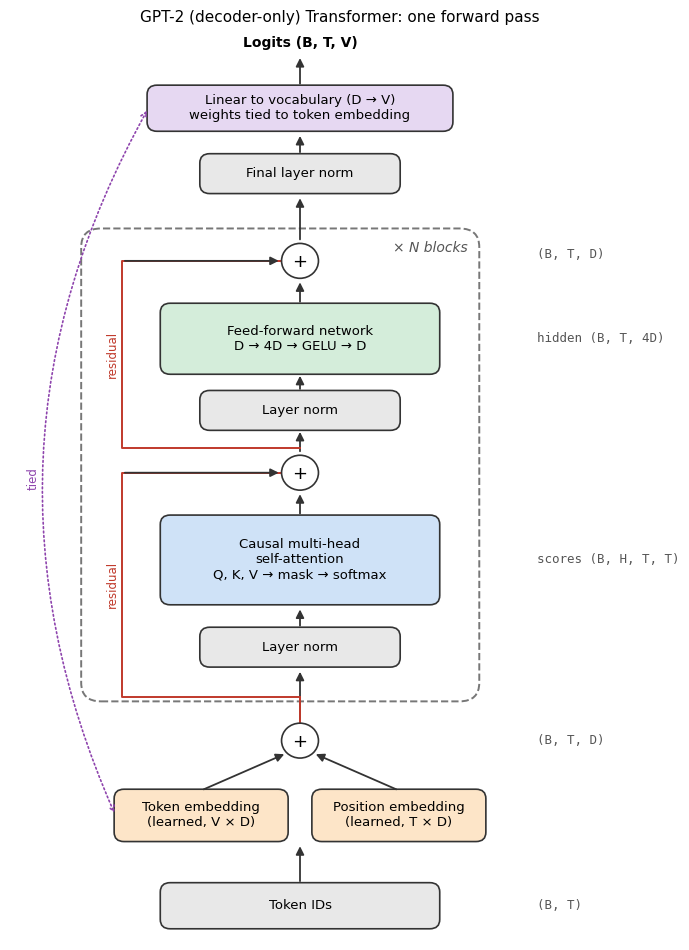

In [4]:
from matplotlib.patches import FancyBboxPatch, Circle, FancyArrowPatch

def draw_gpt2_block():
    fig, ax = plt.subplots(figsize=(7.2, 9.6))
    ax.set_xlim(0, 10); ax.set_ylim(0, 14.6); ax.axis("off")
    CX = 4.4                                           # x of the main (residual) column

    def box(y, h, text, color, w=4.2, x=CX):
        ax.add_patch(FancyBboxPatch((x - w / 2, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.15",
                                    fc=color, ec="#333333", lw=1.2))
        ax.text(x, y + h / 2, text, ha="center", va="center", fontsize=9.5)

    def arrow(x0, y0, x1, y1, **kw):
        ax.add_patch(FancyArrowPatch((x0, y0), (x1, y1), arrowstyle="-|>", mutation_scale=12,
                                     lw=1.3, color="#333333", **kw))

    def plus(y):
        ax.add_patch(Circle((CX, y), 0.28, fc="white", ec="#333333", lw=1.2, zorder=3))
        ax.text(CX, y - 0.02, "+", ha="center", va="center", fontsize=13, zorder=4)

    def shape(y, text):
        ax.text(8.0, y, text, ha="left", va="center", fontsize=9, color="#555555", family="monospace")

    GRAY, BLUE, GREEN, ORANGE, PURPLE = "#e8e8e8", "#cfe2f7", "#d4edda", "#fde5c8", "#e6d8f2"

    # input and embeddings
    box(0.2, 0.7, "Token IDs", GRAY); shape(0.55, "(B, T)")
    arrow(CX, 0.9, CX, 1.55)
    box(1.6, 0.8, "Token embedding\n(learned, V × D)", ORANGE, w=2.6, x=CX - 1.5)
    box(1.6, 0.8, "Position embedding\n(learned, T × D)", ORANGE, w=2.6, x=CX + 1.5)
    arrow(CX - 1.5, 2.4, CX - 0.2, 3.0); arrow(CX + 1.5, 2.4, CX + 0.2, 3.0)
    plus(3.2); shape(3.2, "(B, T, D)")

    # repeated block
    ax.add_patch(FancyBboxPatch((1.1, 3.85), 6.0, 7.55, boxstyle="round,pad=0.02,rounding_size=0.3",
                                fc="none", ec="#777777", lw=1.4, ls="--"))
    ax.text(6.95, 11.1, "× N blocks", fontsize=10, color="#555555", va="center", ha="right", style="italic")
    arrow(CX, 3.5, CX, 4.35)

    # sub-layer 1: attention
    box(4.4, 0.6, "Layer norm", GRAY, w=3.0)
    arrow(CX, 5.0, CX, 5.35)
    box(5.4, 1.4, "Causal multi-head\nself-attention\nQ, K, V → mask → softmax", BLUE, w=4.2)
    shape(6.1, "scores (B, H, T, T)")
    arrow(CX, 6.8, CX, 7.2)
    plus(7.5)
    # residual skip 1
    ax.plot([CX, 1.7, 1.7, CX - 0.28], [3.9, 3.9, 7.5, 7.5], color="#c0392b", lw=1.4, zorder=1)
    ax.plot([CX, CX], [3.5, 3.9], color="#c0392b", lw=1.4, zorder=1)
    arrow(1.7, 7.5, CX - 0.28, 7.5)
    ax.text(1.55, 5.7, "residual", rotation=90, fontsize=8.5, color="#c0392b", va="center", ha="center")

    # sub-layer 2: feed-forward
    arrow(CX, 7.8, CX, 8.2)
    box(8.2, 0.6, "Layer norm", GRAY, w=3.0)
    arrow(CX, 8.8, CX, 9.1)
    box(9.1, 1.1, "Feed-forward network\nD → 4D → GELU → D", GREEN, w=4.2)
    shape(9.65, "hidden (B, T, 4D)")
    arrow(CX, 10.2, CX, 10.6)
    plus(10.9)
    ax.plot([CX, 1.7, 1.7, CX - 0.28], [7.9, 7.9, 10.9, 10.9], color="#c0392b", lw=1.4, zorder=1)
    arrow(1.7, 10.9, CX - 0.28, 10.9)
    ax.text(1.55, 9.4, "residual", rotation=90, fontsize=8.5, color="#c0392b", va="center", ha="center")
    shape(11.0, "(B, T, D)")

    # output head
    arrow(CX, 11.2, CX, 11.95)
    box(12.0, 0.6, "Final layer norm", GRAY, w=3.0)
    arrow(CX, 12.6, CX, 12.95)
    box(13.0, 0.7, "Linear to vocabulary (D → V)\nweights tied to token embedding", PURPLE, w=4.6)
    arrow(CX, 13.7, CX, 14.2)
    ax.text(CX, 14.4, "Logits (B, T, V)", ha="center", va="center", fontsize=10, weight="bold")
    # tie marker
    ax.annotate("", xy=(CX - 2.8, 2.0), xytext=(CX - 2.3, 13.35),
                arrowprops=dict(arrowstyle="<->", color="#8e44ad", lw=1.2, ls=":", connectionstyle="arc3,rad=0.25"))
    ax.text(0.25, 7.4, "tied", rotation=90, fontsize=8.5, color="#8e44ad", va="center")
    ax.set_title("GPT-2 (decoder-only) Transformer: one forward pass", fontsize=11)
    plt.tight_layout(); plt.show()

draw_gpt2_block()

## 4. Inside causal self-attention

### Queries, keys, and values

Each position's vector is projected three ways:

| Vector | Role | Filing-cabinet picture |
| --- | --- | --- |
| **Query** `q_i` | what position `i` is looking for | a note describing your research topic |
| **Key** `k_j` | what position `j` offers to be matched against | the label on a folder |
| **Value** `v_j` | what position `j` contributes if it is selected | the contents of the folder |

**The computation for position `i`:**

1. Score every allowed key: $q_i\cdot k_j/\sqrt{d_k}$.
2. Turn the scores into weights with softmax.
3. Output the weighted sum of the values.

For “The robot opened the”, a later position might put a large weight on “robot”. Which positions get weight is **learned**, not set by hand.

### One fused projection, then heads

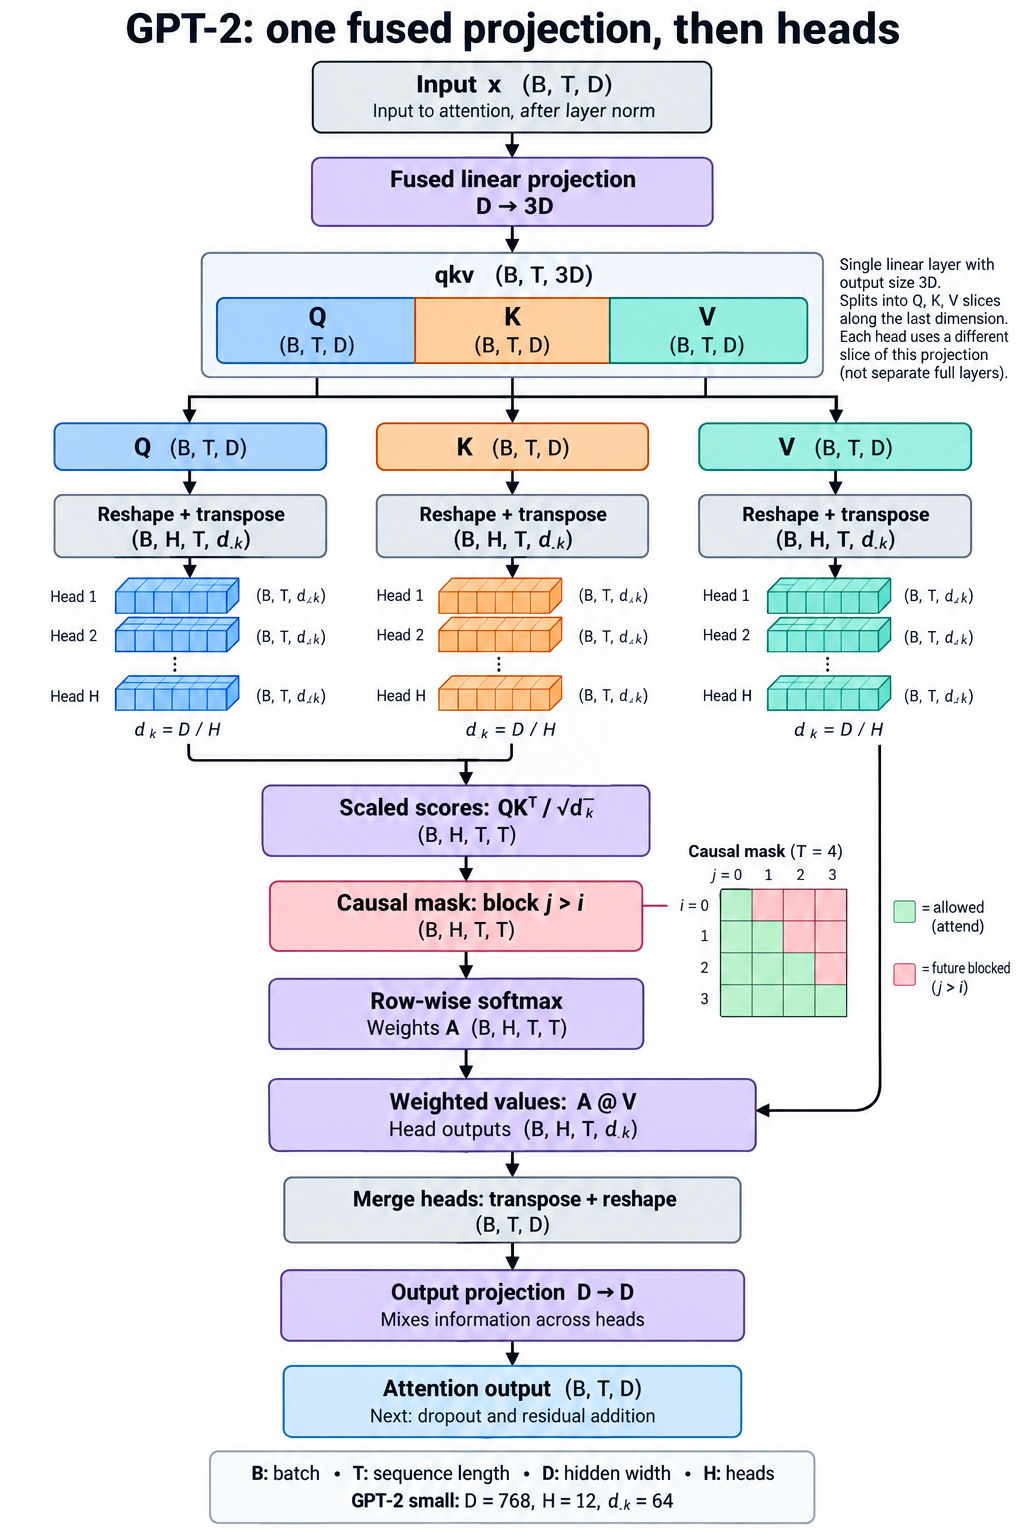

*Figure: Q and K produce masked scores and weights. The weights combine V into head outputs, and the heads are merged before the output projection. Dropout is omitted (GPT-2 applies it after softmax and before the residual add). AI-generated teaching illustration, checked against the notebook's tensor flow.*

```text
x                      (B, T, D)
  │  one linear layer D → 3D
  ▼
qkv                    (B, T, 3D)  ── split ──►  q, k, v   each (B, T, D)
  │  reshape + transpose
  ▼
q, k, v per head       (B, H, T, d_k)            e.g. H = 12, d_k = 64 for GPT-2 small
  │  scores = q kᵀ / √d_k  →  mask  →  softmax
  ▼
weights                (B, H, T, T)
  │  weights @ v
  ▼
head outputs           (B, H, T, d_k)
  │  transpose + reshape (merge heads)
  ▼
merged                 (B, T, D)
  │  output projection D → D  (lets heads mix)
  ▼
attention output       (B, T, D)
```

- **Fused projection:** a single `D → 3D` layer computes Q, K, and V for all heads at once.
- **Heads:** each head works on a `d_k = D / H` slice, so different heads can attend to different positions.
- **Output projection:** mixes the concatenated head outputs into one representation before the residual add.

### The causal mask

$$A=\operatorname{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}+M\right),\qquad M_{ij}=\begin{cases}0&j\le i\\-\infty&j>i\end{cases}$$

```text
          key position →  0  1  2  3
query 0                   ✓  ·  ·  ·
query 1                   ✓  ✓  ·  ·
query 2                   ✓  ✓  ✓  ·
query 3                   ✓  ✓  ✓  ✓
```

- Adding `−∞` before softmax gives future positions **exactly zero** weight, and each row still sums to 1.
- The mask restricts **what each position can read**. It does not force positions to be computed one at a time: during training, all rows are computed together in one matrix operation.

The cell below applies the mask to a 4×4 matrix of **made-up** scores.

In [5]:
tokens = ["robot", "must", "obey", "orders"]
# Illustrative raw scores q_i · k_j / sqrt(d_k): row i = query position, column j = key position.
scores = torch.tensor([
    [2.0, 1.0, 0.5, 0.1],
    [1.5, 1.6, 0.2, 0.3],
    [0.5, 1.2, 1.4, 0.1],
    [0.3, 0.6, 1.1, 1.5],
])
future = torch.triu(torch.ones(4, 4, dtype=torch.bool), diagonal=1)   # True where j > i
masked_scores = scores.masked_fill(future, float("-inf"))
weights = masked_scores.softmax(dim=-1)

print("scores after masking (-inf = blocked):\n", masked_scores)
print("\nattention weights (each row sums to 1):\n", weights.round(decimals=2))

# Toy 2-d value vectors: the output at each position is the weighted sum of the allowed values.
values = torch.tensor([[1.0, 0.0], [0.0, 1.0], [1.0, 1.0], [2.0, 0.0]])
print("\noutputs = weights @ values:\n", (weights @ values).round(decimals=2))
assert torch.allclose(weights.sum(dim=-1), torch.ones(4))
assert (weights[future] == 0).all()

scores after masking (-inf = blocked):
 tensor([[2.0000,   -inf,   -inf,   -inf],
        [1.5000, 1.6000,   -inf,   -inf],
        [0.5000, 1.2000, 1.4000,   -inf],
        [0.3000, 0.6000, 1.1000, 1.5000]])

attention weights (each row sums to 1):
 tensor([[1.0000, 0.0000, 0.0000, 0.0000],
        [0.4800, 0.5200, 0.0000, 0.0000],
        [0.1800, 0.3700, 0.4500, 0.0000],
        [0.1300, 0.1700, 0.2800, 0.4200]])

outputs = weights @ values:
 tensor([[1.0000, 0.0000],
        [0.4800, 0.5200],
        [0.6300, 0.8200],
        [1.2500, 0.4500]])


**Reading the output**

- Row 0 can see only itself, so its weight is 1.
- Row 1 splits its weight between “robot” and “must”, and so on down the rows.
- A larger score gives a larger weight, but softmax normalizes over the **allowed** columns only.

## 5. A small, inspectable GPT-2-style model

| Kept from GPT-2 | Left out |
| --- | --- |
| learned token + position embeddings | dropout |
| fused-QKV causal multi-head attention | GPT-2's exact parameter layout, so its weights are **not** interchangeable with a checkpoint |
| pre-norm blocks, tanh-GELU feed-forward network, final norm | real size: here `V = 16`, `D = 32`, `H = 4`, `N = 2` |
| weight tying | |
| GPT-2 initialization: normal(0, 0.02), with residual output projections scaled by `1/√(2N)` so variance does not grow with depth | |

The `causal` flag lets us switch the mask off later and see what breaks. Until Section 6 trains it, the model's outputs are random.

In [ ]:
class CausalSelfAttention(nn.Module):
    """Multi-head self-attention with one fused Q,K,V projection (as in GPT-2)."""

    def __init__(self, d_model, n_heads, causal=True):
        super().__init__()
        assert d_model % n_heads == 0, "d_model must be divisible by n_heads"
        self.n_heads, self.head_dim, self.causal = n_heads, d_model // n_heads, causal
        self.c_attn = nn.Linear(d_model, 3 * d_model)   # D -> 3D: queries, keys, values
        self.c_proj = nn.Linear(d_model, d_model)       # output projection that mixes the heads

    def forward(self, x):                                # x: (B, T, D)
        B, T, D = x.shape
        q, k, v = self.c_attn(x).split(D, dim=-1)        # each (B, T, D)
        # (B, T, D) -> (B, T, H, d_k) -> (B, H, T, d_k)
        q, k, v = (t.view(B, T, self.n_heads, self.head_dim).transpose(1, 2) for t in (q, k, v))
        scores = q @ k.transpose(-2, -1) / math.sqrt(self.head_dim)      # (B, H, T, T)
        if self.causal:
            future = torch.triu(torch.ones(T, T, dtype=torch.bool, device=x.device), diagonal=1)
            scores = scores.masked_fill(future, float("-inf"))           # block j > i
        weights = scores.softmax(dim=-1)                                  # each row sums to 1
        heads = weights @ v                                               # (B, H, T, d_k)
        merged = heads.transpose(1, 2).reshape(B, T, D)                   # concatenate heads
        # weights = [B, H, T, T] 
        # merged = [B, T, D] = [B, T, H * d_k]
        return self.c_proj(merged), weights


class CausalBlock(nn.Module):
    def __init__(self, d_model, n_heads, causal=True):
        super().__init__()
        self.ln_1 = nn.LayerNorm(d_model)
        self.attn = CausalSelfAttention(d_model, n_heads, causal)
        self.ln_2 = nn.LayerNorm(d_model)
        self.mlp = nn.Sequential(
            nn.Linear(d_model, 4 * d_model),    # [B, T, D] -> [B, T, 4D]
            nn.GELU(approximate="tanh"), # activation
            nn.Linear(4 * d_model, d_model), # [B, T, 4D] -> [B, T, D]
        )

    def forward(self, x):
        attended, weights = self.attn(self.ln_1(x))   # pre-norm, then attention
        # attended = [B, T, D], weights = [B, H, T, T]
        # x = [B, T, D]
        x = x + attended                              # residual add
        x = x + self.mlp(self.ln_2(x))                # pre-norm, feed-forward, residual add
        return x, weights


class TinyGPT2(nn.Module):
    def __init__(self, vocab_size=16, context_size=16, d_model=32, n_heads=4, n_layers=2, causal=True):
        super().__init__()
        self.context_size = context_size
        self.token_embedding = nn.Embedding(vocab_size, d_model)
        self.position_embedding = nn.Embedding(context_size, d_model)
        self.blocks = nn.ModuleList([CausalBlock(d_model, n_heads, causal) for _ in range(n_layers)])
        self.ln_f = nn.LayerNorm(d_model)
        self.lm_head = nn.Linear(d_model, vocab_size, bias=False)
        self._init_weights(n_layers)
        self.lm_head.weight = self.token_embedding.weight  # weight tying: one shared parameter

    def _init_weights(self, n_layers):
        for m in self.modules():
            if isinstance(m, (nn.Linear, nn.Embedding)):
                nn.init.normal_(m.weight, mean=0.0, std=0.02)
                if getattr(m, "bias", None) is not None:
                    nn.init.zeros_(m.bias)
        for block in self.blocks:   # scale residual-path output projections
            for w in (block.attn.c_proj.weight, block.mlp[2].weight):
                nn.init.normal_(w, mean=0.0, std=0.02 / math.sqrt(2 * n_layers))

    def forward(self, input_ids):
        if input_ids.ndim != 2:
            raise ValueError("input_ids must have shape (batch, sequence_length)")
        batch_size, seq_len = input_ids.shape
        if seq_len > self.context_size:
            raise ValueError("sequence exceeds the configured context_size")
        positions = torch.arange(seq_len, device=input_ids.device)
        x = self.token_embedding(input_ids) + self.position_embedding(positions)[None, :, :]
        attention_by_layer = []
        for block in self.blocks:
            x, weights = block(x)
            attention_by_layer.append(weights)
        logits = self.lm_head(self.ln_f(x))
        return logits, attention_by_layer


tiny_model = TinyGPT2().to(device)
toy_ids = torch.tensor([[1, 2, 3, 4]])  # arbitrary IDs, not actual word tokens
logits, attention_by_layer = tiny_model(toy_ids)
print("input IDs:", tuple(toy_ids.shape))
print("logits:", tuple(logits.shape))
print("attention, layer 1:", tuple(attention_by_layer[0].shape))
print("embedding and output weights are shared:",
      tiny_model.lm_head.weight is tiny_model.token_embedding.weight)
assert logits.shape == (1, 4, 16)
assert attention_by_layer[0].shape == (1, 4, 4, 4)

input IDs: (1, 4)
logits: (1, 4, 16)
attention, layer 1: (1, 4, 4, 4)
embedding and output weights are shared: True


**Reading the shapes**

- Logits are `(B, T, V)`: one next-token score vector **per position**.
- Attention is `(B, H, T, T)`: batch, head, query position, key position.
- All 4 query rows come from **one** forward pass. That works because the training input is already known; the mask keeps each row from reading later columns.

### The feed-forward activation: GELU vs. ReLU

Each block's feed-forward network is `Linear(D → 4D)`, then an activation, then `Linear(4D → D)` (`self.mlp` above). Without a nonlinearity in the middle, the two linear layers would collapse into one linear map. GPT-2, like BERT, uses **GELU** (Gaussian Error Linear Unit) there instead of the more familiar **ReLU** (Rectified Linear Unit).

Both can be written as the input multiplied by a **gate** between 0 and 1:

$$\text{ReLU}(x)=x\cdot\mathbb{1}[x>0]\qquad\qquad \text{GELU}(x)=x\cdot\Phi(x)$$

- $\mathbb{1}[x>0]$ is a **hard** gate: 1 for positive inputs, 0 otherwise.
- $\Phi(x)=P(Z\le x)$ for $Z\sim\mathcal{N}(0,1)$ is the standard normal cumulative distribution function. It rises smoothly from 0 to 1, so GELU is a **soft** gate: the more positive $x$ is, the larger the fraction of it that passes.
- **Intuition:** imagine keeping each input at random with probability $\Phi(x)$ and dropping it otherwise. GELU is the *expected* output of that random gate. Large positive inputs are almost always kept, large negative ones almost always dropped, and inputs near 0 are partly kept.

| | ReLU | GELU |
| --- | --- | --- |
| Shape | piecewise linear, kink at 0 | smooth everywhere |
| Negative inputs | output exactly 0 | small negative output (minimum ≈ −0.17 near $x\approx-0.75$), so not monotonic |
| Derivative for $x<0$ | 0: a unit that is always negative gets no gradient ("dead ReLU") | nonzero near 0, so some gradient still flows |
| Derivative at 0 | undefined (jumps from 0 to 1; PyTorch uses 0) | $\Phi(0)=0.5$, from $\text{GELU}'(x)=\Phi(x)+x\,\varphi(x)$, with $\varphi$ the normal density |
| Large $\lvert x\rvert$ | — | practically the same as ReLU |
| Cost | one comparison | needs $\Phi$ (the error function) or an approximation |

**The approximation GPT-2 uses.** GPT-2 computes GELU with a tanh formula, which `nn.GELU(approximate="tanh")` in `CausalBlock` reproduces:

$$\text{GELU}(x)\approx 0.5\,x\left(1+\tanh\!\left[\sqrt{2/\pi}\,\left(x+0.044715\,x^{3}\right)\right]\right)$$

The difference from the exact form is tiny. It matters only when you want to match a pretrained checkpoint's numbers exactly.

**Why Transformers use it.** The reasons are mainly empirical: in the original GELU paper and later Transformer work it matched or slightly beat ReLU, and its smoothness and small negative-side gradient are thought to ease optimization. It is not a large win in every setting. Newer LLMs often use related smooth gates such as SiLU, $x\cdot\sigma(x)$, or gated variants such as SwiGLU.

The cell compares the three functions numerically and plots them with their derivatives, computed by autograd.

    x    Φ(x)   GELU(x)  ReLU(x)
 -2.0   0.023    -0.046    0.000
 -1.0   0.159    -0.159    0.000
 -0.5   0.309    -0.154    0.000
  0.0   0.500     0.000    0.000
  0.5   0.691     0.346    0.500
  1.0   0.841     0.841    1.000
  2.0   0.977     1.954    2.000

GELU minimum: -0.170 at x = -0.75
largest |exact - tanh| on [-4, 4]: 4.7e-04


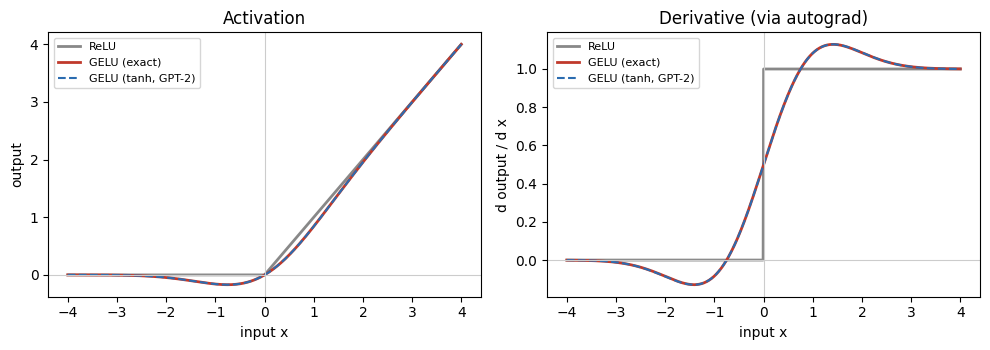

In [3]:
x = torch.linspace(-4, 4, 801, requires_grad=True)
activations = {
    "ReLU": F.relu,
    "GELU (exact)": F.gelu,
    "GELU (tanh, GPT-2)": lambda t: F.gelu(t, approximate="tanh"),
}
values, grads = {}, {}
for name, fn in activations.items():
    y = fn(x)
    grads[name] = torch.autograd.grad(y.sum(), x)[0]      # elementwise derivative dy/dx
    values[name] = y.detach()
xs = x.detach()

print(f"{'x':>5} {'Φ(x)':>7} {'GELU(x)':>9} {'ReLU(x)':>8}")
for v in (-2.0, -1.0, -0.5, 0.0, 0.5, 1.0, 2.0):
    i = int(torch.argmin((xs - v).abs()))
    phi = 0.5 * (1 + math.erf(v / math.sqrt(2)))           # standard normal CDF
    print(f"{v:5.1f} {phi:7.3f} {values['GELU (exact)'][i]:9.3f} {values['ReLU'][i]:8.3f}")

i_min = int(values["GELU (exact)"].argmin())
print(f"\nGELU minimum: {values['GELU (exact)'][i_min]:.3f} at x = {xs[i_min]:.2f}")
print(f"largest |exact - tanh| on [-4, 4]: {(values['GELU (exact)'] - values['GELU (tanh, GPT-2)']).abs().max():.1e}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
styles = {"ReLU": dict(color="#888888", lw=2), "GELU (exact)": dict(color="#c0392b", lw=2),
          "GELU (tanh, GPT-2)": dict(color="#2b6cb0", lw=1.5, ls="--")}
for name in activations:
    axes[0].plot(xs, values[name], label=name, **styles[name])
    axes[1].plot(xs, grads[name], label=name, **styles[name])
axes[0].set_title("Activation"); axes[0].set_ylabel("output")
axes[1].set_title("Derivative (via autograd)"); axes[1].set_ylabel("d output / d x")
for ax in axes:
    ax.axhline(0, color="#cccccc", lw=0.8); ax.axvline(0, color="#cccccc", lw=0.8)
    ax.set_xlabel("input x"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Reading the output**

- The printed values show GELU $= x\cdot\Phi(x)$ directly: at $x=1$ about 84% of the input passes; at $x=-1$ about 16% of it passes, and the result is negative.
- **Left plot:** for large $\lvert x\rvert$ the curves overlap. Near 0, GELU bends smoothly and dips slightly below zero for negative inputs, where ReLU is flat at 0.
- **Right plot:** ReLU's derivative is a step from 0 to 1. GELU's derivative changes smoothly, is 0.5 at the origin, and is still nonzero for moderately negative inputs. It overshoots 1 for inputs above about $0.75$ (peaking near 1.13) and is slightly negative below about $-0.75$, which is the dip in the left plot.
- The exact and tanh versions lie on top of each other; the printed maximum gap shows how small the approximation error is.

### Where do the parameters live?

For width `D`, `N` blocks, vocabulary `V`, and context length `T`:

In layer norm for each token (vector of size D) we learn gamma and beta. Hence for each layer-norm we have 2D params.

For linear layer nn.Linear(D, 3D) the weight matrix has 3D^2 parameters and the bias term has 3D parameters.
| Component (per block) | Parameters |
| --- | --- |
| Layer norm 1 + layer norm 2 | `4D` |
| Fused Q,K,V projection (`D → 3D`, with bias) | `3D² + 3D` |
| Attention output projection (`D → D`) | `D² + D` |
| Feed-forward network (`D → 4D → D`) | `8D² + 5D` |
| **Block total** | **`12D² + 13D`** |

$$\text{params}=\underbrace{VD}_{\text{token table}}+\underbrace{TD}_{\text{positions}}+N\,(12D^2+13D)+\underbrace{2D}_{\text{final norm}}\qquad(\text{tied output head adds }0)$$

- In wide models the `12D²` term dominates.
- **Two-thirds** of each block's parameters are in the feed-forward network (`8D²`); attention has `4D²`.

In [8]:
def gpt2_param_count(vocab_size, context_size, d_model, n_layers):
    per_block = 12 * d_model**2 + 13 * d_model
    return vocab_size * d_model + context_size * d_model + n_layers * per_block + 2 * d_model

actual = sum(p.numel() for p in tiny_model.parameters())   # parameters() counts the tied weight once
formula = gpt2_param_count(vocab_size=16, context_size=16, d_model=32, n_layers=2)
print("TinyGPT2 parameters:", actual, "| formula:", formula)
assert actual == formula

# The same formula for the original smallest GPT-2 configuration (no model is built or downloaded).
small = gpt2_param_count(vocab_size=50257, context_size=1024, d_model=768, n_layers=12)
print(f"GPT-2 small by formula: {small:,}")
print(f"  of which token embedding table: {50257 * 768:,}")
print(f"  of which transformer blocks:    {12 * (12 * 768**2 + 13 * 768):,}")

TinyGPT2 parameters: 26496 | formula: 26496
GPT-2 small by formula: 124,439,808
  of which token embedding table: 38,597,376
  of which transformer blocks:    85,054,464


- GPT-2 small comes out at **~124M** parameters. Section 8 checks this against the real checkpoint.
- Without weight tying, the model would have another `V·D ≈ 38.6M` parameters.

### Verifying that the model is causal

**Visual check.** One attention head of the untrained model. Everything above the diagonal should be zero.

tensor([[1.0000, 0.0000, 0.0000, 0.0000],
        [0.5060, 0.4940, 0.0000, 0.0000],
        [0.3340, 0.3340, 0.3330, 0.0000],
        [0.2510, 0.2490, 0.2540, 0.2460]])
All future-position weights are zero: True


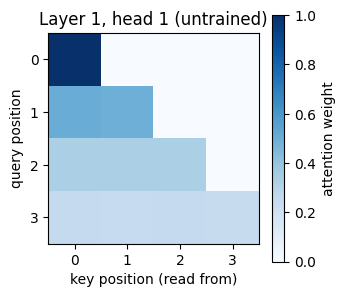

In [9]:
head_0 = attention_by_layer[0][0, 0].detach()
print(head_0.round(decimals=3))
blocked_weights = torch.triu(head_0, diagonal=1)
assert torch.allclose(blocked_weights, torch.zeros_like(blocked_weights))
print("All future-position weights are zero:", bool((blocked_weights == 0).all()))

fig, ax = plt.subplots(figsize=(3.4, 3.2))
im = ax.imshow(head_0, cmap="Blues", vmin=0, vmax=1)
ax.set_xlabel("key position (read from)")
ax.set_ylabel("query position")
ax.set_title("Layer 1, head 1 (untrained)")
ax.set_xticks(range(4)); ax.set_yticks(range(4))
fig.colorbar(im, ax=ax, label="attention weight")
plt.show()

- The staircase of zeros comes from the mask alone.
- The nonzero weights are close to uniform because the model is untrained.

**Leakage test.** Two inputs share positions 0–1 and differ at positions 2–3.

- **Causal model:** the logits at positions 0–1 must be identical.
- **Model built with `causal=False`:** positions 0–1 can now see the changed future tokens, so their logits change.

In [10]:
def leakage_check(model):
    """Largest logit change at positions 0-1 and 2-3 when only positions 2-3 are changed."""
    model.eval()
    first = torch.tensor([[1, 2, 3, 4]])
    changed_future = torch.tensor([[1, 2, 9, 10]])
    with torch.inference_mode():
        a, _ = model(first)
        b, _ = model(changed_future)
    return (a[:, :2] - b[:, :2]).abs().max().item(), (a[:, 2:] - b[:, 2:]).abs().max().item()

earlier, later = leakage_check(tiny_model)
print("causal=True : change at positions 0-1 = %.2e, at positions 2-3 = %.2e" % (earlier, later))
assert earlier < 1e-6

torch.manual_seed(SEED)
unmasked_model = TinyGPT2(causal=False)
earlier_u, later_u = leakage_check(unmasked_model)
print("causal=False: change at positions 0-1 = %.2e, at positions 2-3 = %.2e" % (earlier_u, later_u))
assert earlier_u > earlier   # earlier positions now see the changed future tokens

causal=True : change at positions 0-1 = 0.00e+00, at positions 2-3 = 5.60e-01
causal=False: change at positions 0-1 = 3.63e-02, at positions 2-3 = 5.59e-01


The change in the unmasked model is small only because untrained weights are small. What matters is that it is not zero.

**Prefix-consistency test.** There are two ways to get the model's prediction at position `t`:

- **Way A (what training does):** run the model once on the **whole** sequence, then read the output at position `t`.
- **Way B (what generation does):** cut the sequence off after position `t`, run the model on that **shorter prefix** `x[:t+1]`, then read the **last** output. The later tokens don't exist yet.

If the model is truly causal, the two must give the same numbers, because position `t` should never use tokens after `t`. The cell below checks this for every `t` and reports the largest difference.

In [11]:
tiny_model.eval()
seq = torch.tensor([[1, 2, 3, 1, 2, 4]])
with torch.inference_mode():
    full_logits, _ = tiny_model(seq)
    max_diff = max(
        (full_logits[:, t] - tiny_model(seq[:, :t + 1])[0][:, -1]).abs().max().item()
        for t in range(seq.size(1))
    )
print(f"largest difference, full pass vs. prefix-only passes: {max_diff:.2e}")
assert max_diff < 1e-5

largest difference, full pass vs. prefix-only passes: 5.96e-08


> **Why this matters:** one parallel pass over `T` tokens computes **exactly** what `T` separate prefix runs would. This is why training can score every position at once (Section 6), and why a key–value cache can reuse past computations during generation (Section 7).

## 6. Training: shifted next-token prediction

For a sequence `[A, B, C, D, E]`, the input is `[A, B, C, D]` and the targets are the same sequence shifted left by one, `[B, C, D, E]`:

| Position | Visible prefix | Target |
| --- | --- | --- |
| 0 | `A` | `B` |
| 1 | `A B` | `C` |
| 2 | `A B C` | `D` |
| 3 | `A B C D` | `E` |

- **Loss** at position `t`: $-\log\operatorname{softmax}(z_{t})_{y_{t+1}}$, averaged over all `B × T` predictions (`F.cross_entropy`).
- **Padding:** a padded batch must also leave padding targets out of the loss. The causal mask does not do that.
- **Sanity check:** an untrained model spreads probability roughly evenly, `1/V` per token, so the first loss should be close to **ln V**.
  - Much **above** ln V usually means badly scaled initialization or a bug.
  - Much **below** ln V suggests the model can see the labels (leakage).

### A short training run on a toy pattern

- **Data:** the cycle `1 2 3 1 2 4`, repeated. After `1 2`, the next token is `3` or `4` depending on what came **before** the `1`. A model that only looks at the current token cannot reach zero loss, so attention is needed.
- **Batches:** 17-token windows starting at random offsets. The first 16 tokens are inputs; the last 16 (shifted by one) are targets.
- **Scope:** this is a small demonstration that optimization works, not a language-modeling result. Real GPT-2 was pretrained on WebText, which needs a large corpus and a lot of compute.

loss at step 1: 2.813 | ln(V) = 2.773 | loss at step 300: 0.0347


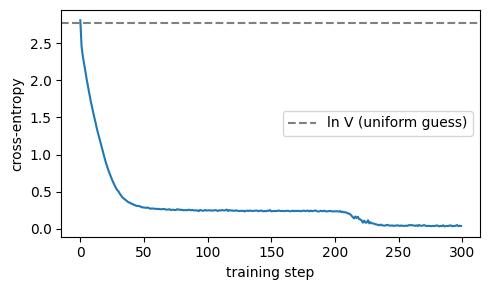

In [12]:
CYCLE = [1, 2, 3, 1, 2, 4]

def make_batch(batch_size, length=17):
    offsets = torch.randint(0, len(CYCLE), (batch_size,))
    rows = [[CYCLE[(int(o) + i) % len(CYCLE)] for i in range(length)] for o in offsets]
    seq = torch.tensor(rows)
    return seq[:, :-1], seq[:, 1:]          # inputs and shifted targets, each (B, 16)

torch.manual_seed(SEED)
model = TinyGPT2().to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-3)
losses = []
model.train()
for step in range(300):
    x, y = make_batch(32)
    logits, _ = model(x)
    loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), y.reshape(-1))
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
print("loss at step 1: %.3f | ln(V) = %.3f | loss at step 300: %.4f" % (losses[0], math.log(16), losses[-1]))

plt.figure(figsize=(5, 3))
plt.plot(losses)
plt.axhline(math.log(16), color="gray", linestyle="--", label="ln V (uniform guess)")
plt.xlabel("training step"); plt.ylabel("cross-entropy"); plt.legend(); plt.tight_layout(); plt.show()
assert losses[-1] < 0.3 * losses[0]

**Reading the curve**

- It starts near **ln V**, which passes the sanity check.
- It falls toward zero because the pattern is fully predictable.
- It may plateau before a second drop. A plausible reading is that the model first learns what the current token alone predicts, and later learns the `1 2 → 3 or 4` decision, which needs earlier positions. Where the plateau falls depends on the seed and the hardware.
- There is no held-out set because the pattern *is* the whole distribution. Real language-model training must evaluate on held-out text.

### Attention in the trained model

The last layer's four heads on one sequence. All are lower-triangular because of the mask; where each head puts its weight was learned.

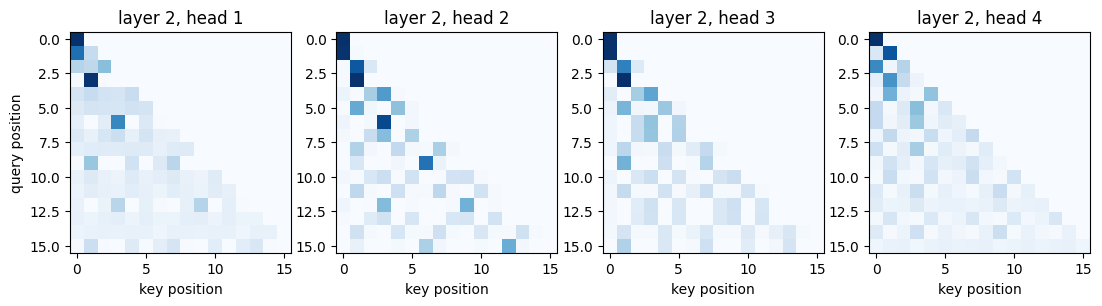

In [13]:
x, _ = make_batch(1)
model.eval()
with torch.inference_mode():
    _, attn_layers = model(x)
last = attn_layers[-1][0]                       # (H, T, T) for the single sequence
fig, axes = plt.subplots(1, 4, figsize=(11, 3))
for h, ax in enumerate(axes):
    ax.imshow(last[h], cmap="Blues", vmin=0, vmax=1)
    ax.set_title(f"layer 2, head {h + 1}")
    ax.set_xlabel("key position"); ax.set_ylabel("query position") if h == 0 else None
plt.tight_layout(); plt.show()

Attention maps are a useful diagnostic, but they are **not** an explanation of the model's reasoning. The residual stream and the feed-forward layers also carry information.

## 7. Generation: one token at a time

```text
Training:    [A B C D] → one pass → logits at ALL 4 positions → loss against [B C D E]
Generation:  [A B C D] → one pass → logits at the LAST position → choose E
             [A B C D E] → one pass → logits at the LAST position → choose F → …
```

Training is parallel because every target is already known. Generation is sequential because each new token is unknown until it is chosen.

| Decoding setting | What it does |
| --- | --- |
| **Greedy** | pick the most probable token (deterministic) |
| **Sampling** | draw a token from the softmax distribution |
| **Temperature** | divide the logits by `T` before softmax: `T < 1` sharpens, `T > 1` flattens |
| **Top-k** | sample only from the `k` highest-scoring tokens |

None of these settings change the weights; they only change how a token is chosen from the same logits.

- **Context window:** only the last `context_size` tokens are visible. Older tokens are dropped.
- **Key–value cache:** our loop reruns the whole window at every step. A cache stores each block's past keys and values, so each step only computes the newest position. Section 5's prefix-consistency test is why this gives the same result. See [the key–value cache notebook](key_value_cache.ipynb).

In [14]:
@torch.no_grad()
def generate(model, prompt_ids, max_new_tokens, greedy=True, temperature=1.0, top_k=None, generator=None):
    """Autoregressive decoding: logits at the LAST position -> choose a token -> append -> repeat."""
    model.eval()
    ids = prompt_ids.clone()
    for _ in range(max_new_tokens):
        window = ids[:, -model.context_size:]            # a fixed context window limits visible history
        logits, _ = model(window)
        next_logits = logits[:, -1, :]                   # (B, V): only the last position is used
        if greedy:
            next_id = next_logits.argmax(dim=-1, keepdim=True)
        else:
            next_logits = next_logits / temperature      # <1 sharpens, >1 flattens the distribution
            if top_k is not None:                        # keep only the k highest-scoring tokens
                kth_best = next_logits.topk(top_k, dim=-1).values[:, -1, None]
                next_logits = next_logits.masked_fill(next_logits < kth_best, float("-inf"))
            next_id = torch.multinomial(next_logits.softmax(dim=-1), num_samples=1, generator=generator)
        ids = torch.cat([ids, next_id], dim=1)
    return ids

prompt = torch.tensor([[1, 2, 3, 1, 2]])                  # the cycle says the next token should be 4
print("pattern    :", [CYCLE[i % 6] for i in range(2 * 6 + 3)])
print("greedy     :", generate(model, prompt, 10)[0].tolist())
g = torch.Generator().manual_seed(SEED)
print("sampled T=1:", generate(model, prompt, 10, greedy=False, generator=g)[0].tolist())
g = torch.Generator().manual_seed(SEED)
print("T=3, top-3 :", generate(model, prompt, 10, greedy=False, temperature=3.0, top_k=3, generator=g)[0].tolist())
assert generate(model, prompt, 1)[0, -1].item() == 4

pattern    : [1, 2, 3, 1, 2, 4, 1, 2, 3, 1, 2, 4, 1, 2, 3]
greedy     : [1, 2, 3, 1, 2, 4, 1, 2, 3, 1, 2, 4, 1, 2, 3]
sampled T=1: [1, 2, 3, 1, 2, 4, 1, 2, 3, 1, 2, 4, 1, 2, 3]
T=3, top-3 : [1, 2, 3, 1, 2, 4, 1, 2, 3, 1, 1, 2, 4, 1, 2]


- **Greedy:** reproduces the cycle, and correctly predicts `4` after `3 1 2`, which requires looking back three tokens.
- **Sampling at T = 1:** stays close to the pattern because the trained distribution is sharp.
- **T = 3 with top-3:** the higher temperature flattens the distribution so other tokens appear; top-k limits the candidates to the 3 best.

## 8. Other tasks as next-token prediction

GPT-2 does only one thing: given a prefix, it gives a probability for every possible next token. It has no separate "summarize" or "translate" mode. To use it for another task, you write the task as **a prefix whose most likely continuation is the answer**.

### 9.1 Writing a task as a prefix

| Task | Prefix given to the model | Continuation we hope for |
| --- | --- | --- |
| Summarization | `<article text>` + `TL;DR:` | a short summary |
| Translation | a few `english sentence = french sentence` pairs, then `The cat sleeps. =` | `Le chat dort.` |
| Question answering | `Q: Who wrote On the Origin of Species?` + `A:` | `Charles Darwin` |
| Sentiment | `Review: The film was dull.` + `Sentiment:` | `negative` |
| Few-shot classification | a few labelled examples, then one unlabelled example | its label |

Why can this work at all? The training text already contains such patterns. "TL;DR:" ("too long; didn't read") is a common web convention placed before a short summary. "Q: … A: …" appears on FAQ pages. The GPT-2 paper shows English sentences followed by their French translations occurring naturally in its training set, WebText (Radford et al., 2019, Table 1). To predict the next token well on such text, the model has to pick up on what usually follows these cues. Nobody trained it to summarize; the behavior is a side effect of learning to continue text.

Mechanically, nothing new is needed. The prompt goes through the same causal forward pass, and the answer is produced by the same loop as in Section 7: predict, append, repeat. **Decoding choices are part of the method.** For summarization, the paper sampled 100 tokens with top-k sampling (k = 2) and kept the first 3 generated sentences as the summary.

### 9.2 How well it works: weak and unreliable

**Zero-shot** means the model gets no task-specific training, only a prompt. The prompt may include a few examples (for translation and question answering the paper used example pairs), but the weights never change. The GPT-2 paper reports these results for its **largest** model (1.5B parameters, about 12× the 124M checkpoint in Section 8):

| Task (dataset) | GPT-2, zero-shot | Comparison reported in the paper |
| --- | --- | --- |
| Summarization (CNN/Daily Mail, average ROUGE) | 21.40 | 20.98 for 3 random sentences from the article; 31.55 for the first 3 sentences; 15.03 for GPT-2 **without** `TL;DR:` |
| Translation, English → French (WMT-14, BLEU) | 5 | slightly worse than word-by-word dictionary substitution |
| Translation, French → English (WMT-14, BLEU) | 11.5 | 33.5 for the best unsupervised system at the time |
| Open-domain questions (Natural Questions, exact match) | 4.1% | 30–50% for systems that combine retrieval with reading |
| Reading comprehension (CoQA, F1) | 55 | matches or beats 3 of 4 trained baselines; humans reach 89 |

How to read this table:

- **The prompt really does select the task.** Removing `TL;DR:` drops the summarization score by 6.4 points. The model's behavior changes with the wording of the input alone.
- **"Can do the task" is not the same as "does it well."** The summaries barely beat random sentences, and the paper notes that they often confuse details, such as how many cars were in a crash.
- **Good scores need a careful look.** On CoQA the document is in the prompt, and the paper reports that GPT-2 often relies on simple heuristics, such as answering a "who" question with a name from the document.
- **Scale mattered.** All these abilities improved steadily with model size, which is the trend GPT-3 and later models pushed much further. The 124M model in Section 8 is much weaker than the numbers above.

The practical lesson: a task phrased as a prompt has to be **evaluated**, with fixed prompts, decoding settings, and a baseline, before you trust it. Small changes to the wording can change the output a lot.

### 9.3 Three ways to adapt the model

When prompting alone is not good enough, there are three levers. Each changes something different:

| Approach | What changes | What stays fixed | Example |
| --- | --- | --- | --- |
| **Prompting** | only the input text: instructions, format, examples | the weights | add `TL;DR:`, or show 3 labelled reviews before the new one |
| **Fine-tuning** | the **weights**, by training on task examples | the architecture and the loss | train on `article TL;DR: summary` texts |
| **Retrieval** (retrieval-augmented generation, RAG) | the **context**: retrieved documents are placed in the prompt | the weights | find the relevant handbook paragraph and put it before the question |

- **Fine-tuning reuses the Section 6 loss**: shifted targets and cross-entropy, but on task examples instead of general web text. A common choice is to score only the answer tokens, so the model is not trained to reproduce the prompt. Parameter-efficient methods such as LoRA (Module 3) update a small number of added parameters instead of all the weights. See the [GPT-2 fine-tuning notebook](../../module3/lectures/fine_tuning/gpt2_fine_tuning.ipynb).
- **Retrieval teaches the model nothing new.** The model still only continues text, but now the facts it needs are in the context window, where attention can read them. Remove the documents and the knowledge is gone. This is why retrieval suits facts that change often or are private.
- **Prompting and retrieval both act on the input.** Prompting mostly adds instructions, format, or examples; retrieval adds information.

### 9.4 Beyond text

Next-token prediction works on any data that can be written as a sequence of tokens. [Music Transformer](https://arxiv.org/abs/1809.04281) (Huang et al., 2018) represents music as events such as note-on, note-off, and time-shift, and trains a decoder-only Transformer to predict the next event. The model from Sections 3–6 never needs to know what its tokens stand for.

### 9.5 Likely is not the same as true

The training loss rewards giving high probability to **what came next in the training text**. Nothing in it checks whether a statement is correct. A model trained this way:

- can repeat a false claim that is common in its training data;
- tends to go along with a false assumption in the prompt, because a continuation that accepts the premise is often the most likely one;
- produces fluent, confident text whether or not it has the answer, which is called **hallucination**.

The paper's own question-answering examples show this. Asked *"What US state forms the western boundary of Montana?"*, GPT-2 answered *"Montana"* with 52.3% probability. Retrieval can help by putting real sources in the context, but the model can still ignore or misread them. Generated text has to be checked against evidence.

## 10. Check your understanding

1. In a four-token input, which columns may query row 1 attend to, and which does the mask block?
2. Why can training score every position in one pass, while generation needs one pass per new token? Which test in Section 5 shows the two are consistent?
3. If you remove the mask but keep the shifted targets, what leaks? Which test detects it?
4. Why does one mask inside attention make the whole model causal?
5. How do GPT-2's next-token objective and BERT's masked-token objective use context differently?
6. Give the shapes of `q`, `k`, `v` before and after splitting into heads. Why does the output projection come after the heads are merged?
7. An untrained model with `V = 16` starts at loss 9.0. What does ln 16 tell you, and what might be wrong?
8. Which part of a block has more parameters, attention or the feed-forward network? What does weight tying save?
9. Do temperature or top-k change the model's weights or its training loss?
10. A fluent continuation makes an unsupported factual claim. What does this tell you about next-token prediction?
11. Write ReLU and GELU as “input × gate”. What is the gate in each case, and what happens to the gradient for a moderately negative input such as $x=-1$?

**Practice:** the [GPT-2 lab](../labs/gpt2_causal_lm/gpt2_causal_lm_lab.ipynb) has you write the mask, handle padding, build a leaking model, count parameters, implement top-k sampling, and train and decode a small model.

**Further reading:** [Radford et al. (2019), *Language Models are Unsupervised Multitask Learners*](https://cdn.openai.com/better-language-models/language-models.pdf) · [Hugging Face GPT-2 docs](https://huggingface.co/docs/transformers/model_doc/gpt2) · [GPT-2 model card](https://huggingface.co/openai-community/gpt2) · [Jay Alammar, *The Illustrated GPT-2*](https://jalammar.github.io/illustrated-gpt2/).